# Approach 1: Text-Window FNN

This is the main notebook for the selected combined method. It shows completed training outputs and graphs without retraining. The active submission uses a fresh FNN fitted on all eligible training responses.

In [1]:
from pathlib import Path
import json
import os
import sys

os.environ['KERAS_BACKEND'] = 'torch'
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dharaneesh/approach1.py').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook inside the dl-project repository.')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE = REPO / 'dharaneesh'
DATA_DIR = Path(os.environ.get('AIMS_DATA_DIR', str(REPO.parent)))
report = json.loads((HERE / 'results.json').read_text())
print('Project:', HERE)
print('Active model:', report['active_model'])

Project: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh
Active model: Full-data refit


## Architecture

Task text -> up to four selected 254-token content windows -> frozen MiniLM SBERT -> normalized mean pooling (384 features). Model name, provider, harness, harness version, and reasoning effort -> normalized feature hashing (256 features). Four statistics describe text length, newline count, digit proportion, and selected punctuation proportion.

The 644 inputs feed Dense(32, ReLU) -> Dropout(0.35) -> Dense(16, ReLU) -> Dropout(0.35) -> Dense(1, sigmoid). The hidden kernels use L2 = 0.0001. The FNN has 21,185 trainable parameters and predicts the probability that the subject model answers correctly. SBERT stays frozen. There is no ensemble, logistic replacement, confidence shrinkage, or revealed-label adaptation.

## Final Training on All Data

The active model is trained from fresh initialization on all 136,282 eligible native-binary responses across four benchmarks. This includes the earlier 26,977 validation responses. The two nonbinary dataset sections are not relabeled or included. Joins are validated, inputs are finite float32 values, and fitting weights give every model-benchmark pair equal total influence.

The four LOBO inner-validation runs selected epochs 9, 4, 5, and 13. Their median fixes the final refit at 7 epochs before training begins. The per-epoch median learning-rate history gives 0.0005 for all seven epochs. The full-data fit has no validation set, live plateau scheduler, or early stopping. It retains the same architecture, Brier loss, Adam optimizer, batch size 512, dropout, and L2 regularization.

The figures below describe fitting the training data. They are not validation, LOBO, or CodaBench scores.

seed                                                                   42
refit_on_all_public                                                  True
training_rows                                                      136282
validation_rows                                                         0
training_prompts                                                     8794
training_pairs                                                        147
benchmarks              [multi_swebench, real_webagents, researchcodeb...
epochs_completed                                                        7
training_seconds                                                 28.79072
training_fit_metrics    {'row_brier': 0.1758472987423132, 'pair_brier'...
evaluation_note         Full-data metrics are in-sample, not validatio...
Name: Full-data refit, dtype: object

epochs                                                                    7
learning_rates            [0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.000...
inner_best_epochs                                             [9, 4, 5, 13]
epoch_policy              Median inner-validation best epoch, rounded ha...
learning_rate_policy      Per-epoch median of the four inner-validation ...
outer_test_scores_used                                                False
early_stopping                                                        False
validation_rows                                                           0
note                      The schedule is frozen before fitting; no vali...
Name: Policy frozen before training, dtype: object

,accuracy,brier_score,loss,learning_rate,train_pair_brier,train_row_accuracy,epoch
0,0.710269,0.199650,0.206232,0.0005,0.175032,0.671417,1
1,0.729636,0.172814,0.178630,0.0005,0.160166,0.685490,2
2,0.755969,0.161314,0.167191,0.0005,0.149822,0.692755,3
3,0.778640,0.153385,0.159578,0.0005,0.143426,0.696101,4
4,0.789379,0.146739,0.153266,0.0005,0.136624,0.700415,5
5,0.799438,0.142194,0.149078,0.0005,0.133089,0.703725,6
6,0.807454,0.137973,0.145176,0.0005,0.128766,0.708039,7


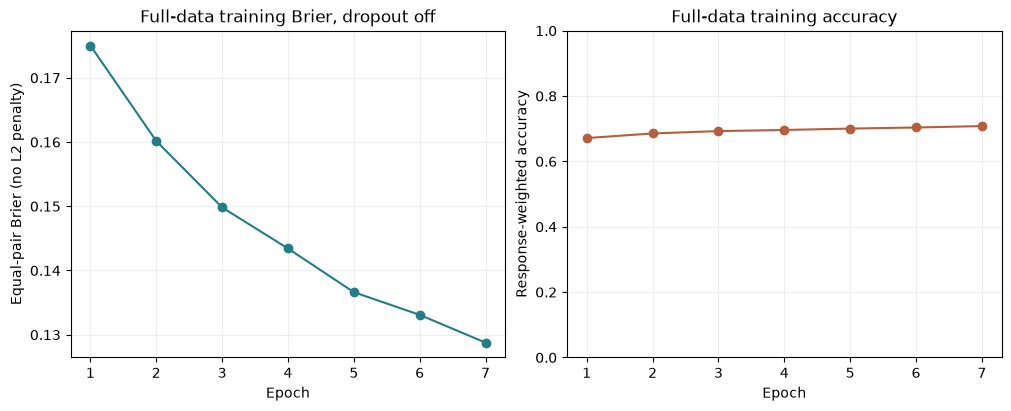

In [2]:
final = report['final']
display(pd.Series({k: v for k, v in final.items() if k not in ['history', 'plan', 'model']}, name='Full-data refit'))
display(pd.Series(final['plan'], name='Policy frozen before training'))
final_history = pd.DataFrame(final['history'])
display(final_history.round(6))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
axes[0].plot(final_history['epoch'], final_history['train_pair_brier'], marker='o', color='#237c87')
axes[0].set(title='Full-data training Brier, dropout off', xlabel='Epoch', ylabel='Equal-pair Brier (no L2 penalty)')
axes[1].plot(final_history['epoch'], final_history['train_row_accuracy'], marker='o', color='#b45e3b')
axes[1].set(title='Full-data training accuracy', xlabel='Epoch', ylabel='Response-weighted accuracy', ylim=(0, 1))
for axis in axes:
    axis.set_xticks(final_history['epoch'])
    axis.grid(alpha=0.2)
display(fig)
plt.close(fig)

## Earlier 80/20 Development Run

Before the final refit, complete prompts were grouped into an 80/20 development split with split seed 42. Duplicate prompts could not cross that split. Training used a maximum of 20 epochs, early stopping with patience four, and ReduceLROnPlateau with patience two. Checkpoints monitored pure equal-pair validation Brier, without L2 penalties. The seed-42 run selected epoch 12 of 16; its first learning-rate reduction took effect in epoch 15, after the selected checkpoint.

Across initialization seeds 42, 123, and 2026, validation Brier averaged 0.161223 with sample SD 0.000700. This familiar-benchmark validation also selected checkpoints, so it is not an independent test. Its compiled checkpoint is archived locally and is no longer the submitted model.

,seed,row_brier,pair_brier,accuracy,row_ece,pairs,rows,best_epoch,epochs_completed,training_seconds
0,42,0.191507,0.161935,0.664010,0.057952,147,26977,12,16,29.808062
1,123,0.191404,0.161200,0.659339,0.060816,147,26977,6,10,18.261842
2,2026,0.193767,0.160535,0.662601,0.068763,147,26977,6,10,18.798839


,accuracy,brier_score,loss,val_accuracy,val_brier_score,val_loss,val_pair_brier,learning_rate,train_pair_brier,train_row_accuracy,val_row_accuracy,epoch
0,0.711400,0.203383,0.210098,0.704988,0.186167,0.192127,0.186167,0.00050,0.177636,0.673967,0.661082,1
1,0.724473,0.175930,0.181738,0.704929,0.174825,0.180553,0.174825,0.00050,0.163996,0.674141,0.661786,2
2,0.743443,0.163862,0.169608,0.744185,0.170221,0.176042,0.170221,0.00050,0.153902,0.698742,0.661489,3
3,0.772157,0.155427,0.161377,0.752795,0.166239,0.172336,0.166239,0.00050,0.145626,0.699657,0.661267,4
4,0.789705,0.148673,0.154940,0.755473,0.165420,0.171857,0.165420,0.00050,0.139043,0.703856,0.662379,5
5,0.800052,0.143597,0.150205,0.761059,0.163168,0.169895,0.163168,0.00050,0.133466,0.706390,0.663676,6
6,0.809206,0.138839,0.145717,0.751448,0.164444,0.171458,0.164444,0.00050,0.129415,0.707781,0.660563,7
7,0.814924,0.135466,0.142632,0.760891,0.162910,0.170215,0.162910,0.00050,0.125984,0.709464,0.663528,8
8,0.816863,0.132522,0.139958,0.753941,0.163681,0.171236,0.163681,0.00050,0.123061,0.711733,0.664270,9
9,0.821688,0.130833,0.138534,0.756380,0.162804,0.170627,0.162803,0.00050,0.119331,0.711660,0.660711,10


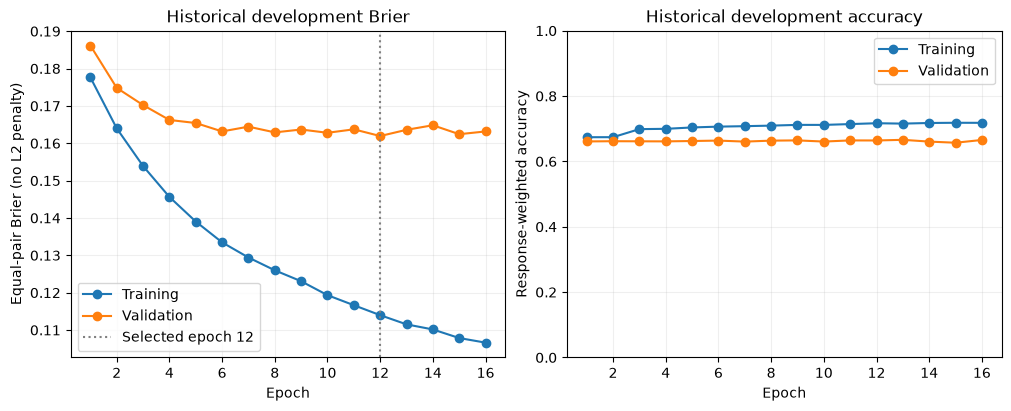

In [3]:
validation = report['validation']
display(pd.DataFrame(validation['seed_results']).round(6))
history = pd.DataFrame(validation['history'])
display(history.round(6))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for key, label in [('train_pair_brier', 'Training'), ('val_pair_brier', 'Validation')]:
    axes[0].plot(history['epoch'], history[key], marker='o', label=label)
axes[0].axvline(12, linestyle=':', color='gray', label='Selected epoch 12')
axes[0].set(title='Historical development Brier', xlabel='Epoch', ylabel='Equal-pair Brier (no L2 penalty)')
for key, label in [('train_row_accuracy', 'Training'), ('val_row_accuracy', 'Validation')]:
    axes[1].plot(history['epoch'], history[key], marker='o', label=label)
axes[1].set(title='Historical development accuracy', xlabel='Epoch', ylabel='Response-weighted accuracy', ylim=(0, 1))
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
display(fig)
plt.close(fig)

## Held-Out Benchmark Evaluation

The existing four-fold LOBO procedure held out one complete benchmark at a time. Each fold trained a fresh FNN on the other benchmarks and used an inner prompt-grouped 80/20 split for checkpoint selection. The outer test benchmark and duplicate test prompts were excluded from both inner subsets.

Equal-pair LOBO Brier is 0.261456, compared with 0.283996 for the original FNN. The current method still loses to constant-0.5 predictions (0.250000) and the fitting-mean baseline (0.231825). LOBO used initialization seed 42 on public development benchmarks. It evaluates the recipe using four separate models, not the final all-data checkpoint, and is not a CodaBench score.

,pair_brier,benchmark_mean_brier,row_brier,row_accuracy,pairs,rows,benchmarks
FNN,0.261456,0.284305,0.299075,0.546433,147.0,136282.0,4.0
Training mean,0.231825,0.257348,0.282284,0.671417,147.0,136282.0,4.0
Constant 0.5,0.250000,0.250000,0.250000,0.328583,147.0,136282.0,4.0


,held_out,predictor,row_brier,pair_brier,accuracy,row_ece,pairs,rows
0,multi_swebench,FNN,0.248523,0.256837,0.560897,0.303505,82,57975
1,multi_swebench,Training mean,0.227538,0.232376,0.852057,0.318562,82,57975
2,multi_swebench,Constant 0.5,0.250000,0.250000,0.147943,0.352057,82,57975
3,real_webagents,FNN,0.249967,0.249450,0.639020,0.142440,33,4449
4,real_webagents,Training mean,0.230559,0.229707,0.642392,0.028878,33,4449
5,real_webagents,Constant 0.5,0.250000,0.250000,0.357608,0.142392,33,4449
6,researchcodebench,FNN,0.287038,0.283689,0.631044,0.219396,31,6784
7,researchcodebench,Training mean,0.232063,0.229195,0.638709,0.036100,31,6784
8,researchcodebench,Constant 0.5,0.250000,0.250000,0.361291,0.138709,31,6784
9,swe_rebench,FNN,0.347245,0.347245,0.519232,0.296867,1,67074


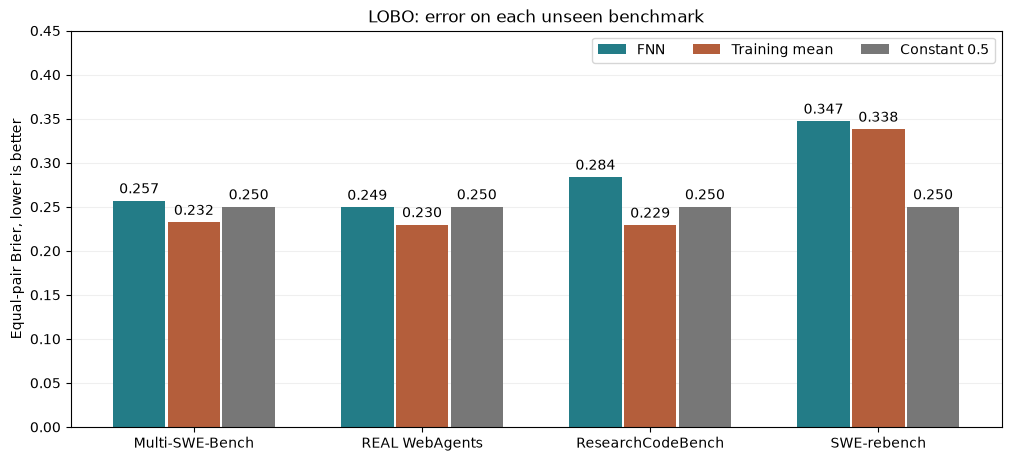

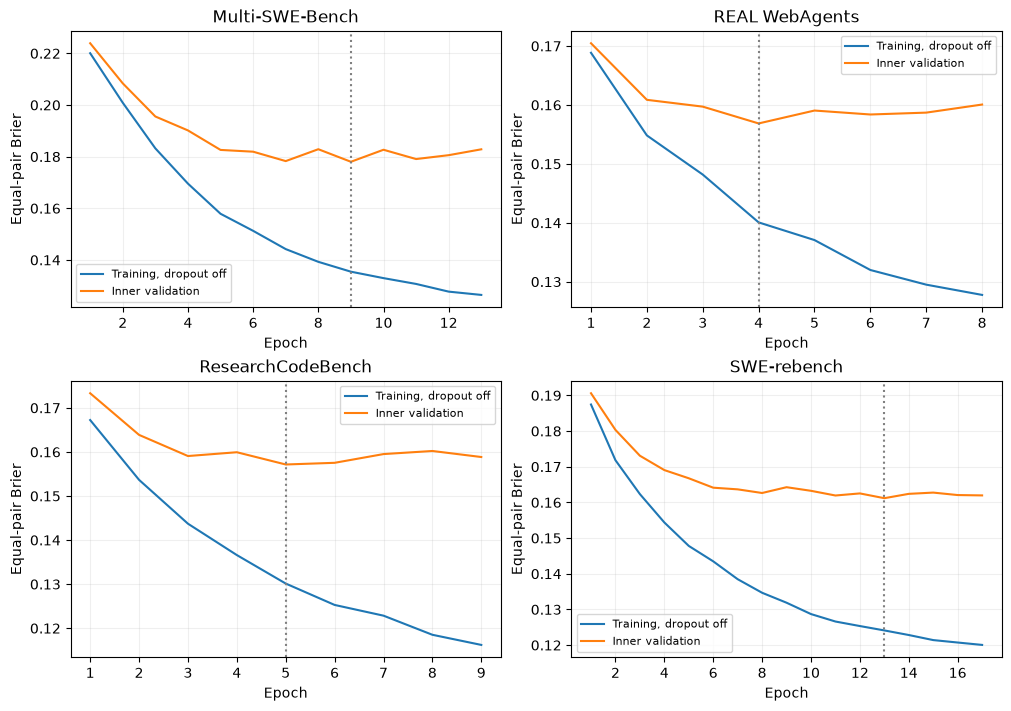

In [4]:
lobo = report['lobo']
display(pd.DataFrame(lobo['aggregate']).T.round(6))
fold_scores = pd.DataFrame(lobo['fold_scores'])
display(fold_scores.round(6))
names = {'multi_swebench':'Multi-SWE-Bench', 'real_webagents':'REAL WebAgents', 'researchcodebench':'ResearchCodeBench', 'swe_rebench':'SWE-rebench'}
sources = sorted(names)
fig, axis = plt.subplots(figsize=(10, 4.5), layout='constrained')
positions = np.arange(len(sources))
for offset, (predictor, color) in enumerate(zip(['FNN', 'Training mean', 'Constant 0.5'], ['#237c87', '#b45e3b', '#777777'])):
    values = fold_scores.loc[fold_scores['predictor'].eq(predictor)].set_index('held_out').loc[sources, 'pair_brier']
    bars = axis.bar(positions + (offset - 1) * 0.24, values, width=0.23, label=predictor, color=color)
    axis.bar_label(bars, fmt='%.3f', padding=3)
axis.set_xticks(positions, [names[source] for source in sources])
axis.set(title='LOBO: error on each unseen benchmark', ylabel='Equal-pair Brier, lower is better', ylim=(0, 0.45))
axis.legend(ncols=3)
axis.grid(axis='y', alpha=0.2)
axis.set_axisbelow(True)
display(fig)
plt.close(fig)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout='constrained')
for axis, fold in zip(axes.flat, lobo['folds']):
    curve = pd.DataFrame(fold['history'])
    axis.plot(curve['epoch'], curve['train_pair_brier'], label='Training, dropout off')
    axis.plot(curve['epoch'], curve['val_pair_brier'], label='Inner validation')
    axis.axvline(fold['best_epoch'], color='gray', linestyle=':')
    axis.set(title=names[fold['held_out']], xlabel='Epoch', ylabel='Equal-pair Brier')
    axis.legend(fontsize=8)
    axis.grid(alpha=0.2)
display(fig)
plt.close(fig)

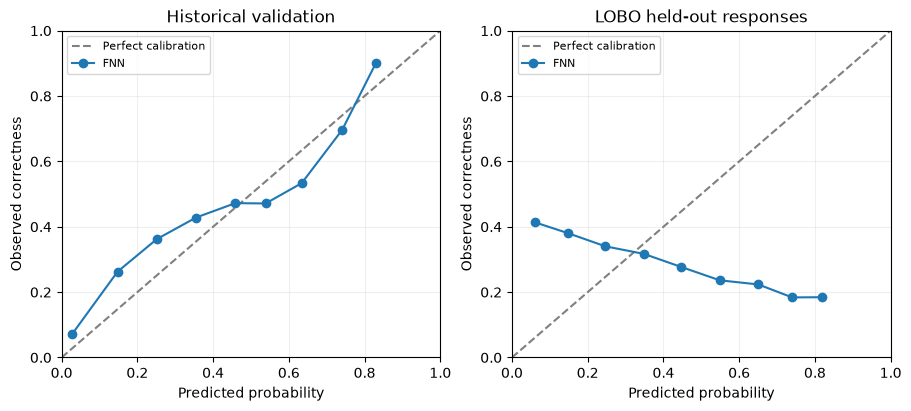

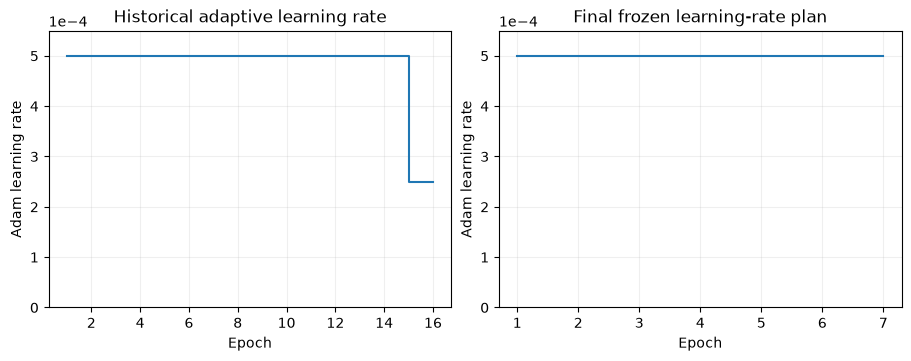

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
for axis, section, title in zip(axes, ['validation', 'lobo'], ['Historical validation', 'LOBO held-out responses']):
    points = report[section]['calibration']
    axis.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
    axis.plot(points['predicted'], points['observed'], marker='o', label='FNN')
    axis.set(title=title, xlabel='Predicted probability', ylabel='Observed correctness', xlim=(0, 1), ylim=(0, 1))
    axis.legend(fontsize=8)
    axis.grid(alpha=0.2)
display(fig)
plt.close(fig)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
axes[0].step(history['epoch'], history['learning_rate'], where='post')
axes[0].set(title='Historical adaptive learning rate', xlabel='Epoch', ylabel='Adam learning rate', ylim=(0, 0.00055))
axes[1].step(final_history['epoch'], final_history['learning_rate'], where='post')
axes[1].set(title='Final frozen learning-rate plan', xlabel='Epoch', ylabel='Adam learning rate', ylim=(0, 0.00055))
for axis in axes:
    axis.grid(alpha=0.2)
    axis.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
display(fig)
plt.close(fig)

## Short Report Summary

The approach combines frozen SBERT embeddings from selected task-text windows with model metadata and simple text statistics. A small FNN with 32 and 16 hidden neurons predicts the probability of a correct answer. Development training used Brier loss, dropout, L2 regularization, early stopping, and learning-rate scheduling.

Local LOBO Brier improved from 0.2840 for the original FNN to 0.2615, although it remained worse than the constant-0.5 and fitting-mean baselines. After development, the final FNN was trained from scratch on all 136,282 eligible responses for seven fixed epochs, using a policy derived from inner validation. Its training metrics are in-sample only; its hidden competition performance remains unknown until submission.

## Submission

The active compiled model is model.keras. Upload submission_fnn.zip manually to CodaBench. The submission folder contains the same predictor, weights, configuration, and frozen encoder. Prediction uses NumPy for the trained FNN and does not need TensorFlow or Keras. All detailed historical artifacts and tests are preserved in a local archive outside this compact repository folder.

In [6]:
from dharaneesh.approach1 import file_sha256
config = json.loads((HERE / 'submission/config.json').read_text())
checks = report['packaging']
assert config['refit_on_all_public'] and config['training_rows'] == 136282 and config['validation_rows'] == 0
assert file_sha256(HERE / 'model.keras') == config['checkpoint_sha256'] == checks['checkpoint_sha256']
assert file_sha256(HERE / 'submission_fnn.zip') == checks['zip_sha256']
print('Compiled final FNN:', HERE / 'model.keras')
print('Submission folder:', HERE / 'submission')
print('Upload file:', HERE / 'submission_fnn.zip')
print('All-data refit:', config['training_rows'], 'responses;', config['refit_epochs'], 'epochs')
print('Checkpoint and ZIP hashes verified.')
display(pd.Series(checks.get('real_task_parity', {}), name='Real-task prediction checks'))

Compiled final FNN: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\model.keras
Submission folder: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission
Upload file: C:\Users\dhara\Downloads\aims\aims\data\measurement-db\dl-project\dharaneesh\submission_fnn.zip
All-data refit: 136282 responses; 7 epochs
Checkpoint and ZIP hashes verified.


cases                                   16
benchmarks                               4
maximum_probability_absolute_error     0.0
revealed_labels_ignored               True
Name: Real-task prediction checks, dtype: object

## Optional New Runs

Leave the switches off to view the saved outputs. Validation and LOBO save separate run folders. Enabling the full-data refit replaces the active compiled model and submission ZIP after fitting and export checks. Set AIMS_DATA_DIR if the dataset is elsewhere; the encoder is restored from the ZIP when needed.

In [7]:
RUN_VALIDATION = False
RUN_LOBO = False
RUN_FULL_REFIT = False

if RUN_VALIDATION or RUN_LOBO or RUN_FULL_REFIT:
    from datetime import datetime
    from dharaneesh.approach1 import restore_encoder, run_training, run_lobo, refit_all_data
    restore_encoder()
    encoder = Path(os.environ.get('AIMS_ENCODER_DIR', str(HERE / 'submission/text_encoder')))
    run_root = DATA_DIR / 'approach1_outputs/experiment_runs'
    stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    for enabled, function, label in [(RUN_VALIDATION, run_training, 'validation'), (RUN_LOBO, run_lobo, 'lobo'), (RUN_FULL_REFIT, refit_all_data, 'full_data')]:
        if enabled:
            function(DATA_DIR, run_root / f'combined_{label}_{stamp}', encoder)
else:
    print('Showing saved results. No training or submission files were changed.')

Showing saved results. No training or submission files were changed.
